# Part 1: Fundamentals Model â€” Base Dataset

Builds the base DataFrame for the structural fundamentals model: one row per presidential election, 1948â€“2024.

**Variables:**
- `year` â€” election year
- `incumbent_party` â€” D or R
- `dem_two_party_share` â€” Dem/(Dem+Rep) popular vote (%)
- `gdp_q2_growth` â€” annualized real GDP growth Q1â†’Q2 of election year (%)
- `approval_rating_june` â€” incumbent president's Gallup approval in June (%)
- `consecutive_terms` â€” terms incumbent party has held going into election
- `open_seat` â€” no sitting president on ballot
- `inflation_q2` â€” CPI YoY change in June of election year (%)

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

FRED_DIR = Path('../data/raw/fred')
OUTPUT_DIR = Path('../data/processed')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## 1. Historical election results and incumbency variables

Sources:
- **Two-party vote**: UCSB American Presidency Project, Dave Leip's Atlas of U.S. Presidential Elections
- **Approval ratings**: Gallup Historical Statistics (used as fallback when FRED APPROVE series is unavailable)
- Three-way races (1968, 1992, 1996, 2000): two-party share calculated as `Dem / (Dem + Rep)`

In [2]:
election_years = [
    1948, 1952, 1956, 1960, 1964, 1968, 1972, 1976,
    1980, 1984, 1988, 1992, 1996, 2000, 2004, 2008,
    2012, 2016, 2020, 2024
]

# Incumbent party at time of election
incumbent_party = [
    'D', 'D', 'R', 'R', 'D', 'D', 'R', 'R',
    'D', 'R', 'R', 'R', 'D', 'D', 'R', 'R',
    'D', 'D', 'R', 'D'
]

# Dem two-party vote share (%)
dem_two_party_share = [
    52.37,  # 1948 Truman
    44.60,  # 1952 Stevenson
    42.25,  # 1956 Stevenson
    50.08,  # 1960 Kennedy
    61.34,  # 1964 Johnson
    49.60,  # 1968 Humphrey (excl. Wallace)
    38.22,  # 1972 McGovern
    51.05,  # 1976 Carter
    44.70,  # 1980 Carter (excl. Anderson)
    40.83,  # 1984 Mondale
    46.09,  # 1988 Dukakis
    53.45,  # 1992 Clinton (excl. Perot)
    54.74,  # 1996 Clinton (excl. Perot)
    50.27,  # 2000 Gore
    48.74,  # 2004 Kerry
    53.69,  # 2008 Obama
    51.96,  # 2012 Obama
    51.11,  # 2016 Clinton
    52.27,  # 2020 Biden
    49.25,  # 2024 Harris (final certified)
]

# Terms incumbent party has held going into this election
consecutive_terms = [
    4, 5, 1, 2, 1, 2, 1, 2,
    1, 1, 2, 3, 1, 2, 1, 2,
    1, 2, 1, 1
]

# No sitting president on the ballot
open_seat = [
    False, True,  False, True,  False, True,  False, False,
    False, False, True,  False, False, True,  False, True,
    False, True,  False, True
]

# Gallup June approval â€” fallback for years not covered by FRED APPROVE
june_approval_fallback = {
    1948: 39, 1952: 32, 1956: 73, 1960: 61, 1964: 74, 1968: 42,
    1972: 62, 1976: 45, 1980: 32, 1984: 54, 1988: 51, 1992: 37,
    1996: 55, 2000: 57, 2004: 48, 2008: 30, 2012: 47, 2016: 51,
    2020: 42, 2024: 38
}

df = pd.DataFrame({
    'year': election_years,
    'incumbent_party': incumbent_party,
    'dem_two_party_share': dem_two_party_share,
    'consecutive_terms': consecutive_terms,
    'open_seat': open_seat,
})

print(f'Base table: {len(df)} elections')
df

Base table: 20 elections


,year,incumbent_party,dem_two_party_share,consecutive_terms,open_seat
0,1948,D,52.37,4,False
1,1952,D,44.60,5,True
2,1956,R,42.25,1,False
3,1960,R,50.08,2,True
4,1964,D,61.34,1,False
5,1968,D,49.60,2,True
6,1972,R,38.22,1,False
7,1976,R,51.05,2,False
8,1980,D,44.70,1,False
9,1984,R,40.83,1,False


## 2. GDP Q2 growth from FRED GDPC1

Annualized real GDP growth rate from Q1 â†’ Q2 of the election year.

Formula: `((Q2 / Q1)^4 - 1) * 100`

This matches the specification used by Abramowitz's Time for Change model.

In [3]:
def load_gdp_q2_growth(fred_dir):
    try:
        gdp = pd.read_csv(fred_dir / 'GDPC1.csv', index_col=0, parse_dates=True)
        gdp.columns = ['gdp']
        gdp['year'] = gdp.index.year
        gdp['quarter'] = gdp.index.quarter

        q1 = gdp[gdp['quarter'] == 1].set_index('year')['gdp']
        q2 = gdp[gdp['quarter'] == 2].set_index('year')['gdp']

        growth = ((q2 / q1) ** 4 - 1) * 100
        growth.name = 'gdp_q2_growth'
        print(f'GDP Q2 growth: {len(growth)} years, {growth.index.min()}-{growth.index.max()}')
        return growth
    except FileNotFoundError:
        print('! GDPC1.csv not found â€” run src/data_collection/fred_pull.py first.')
        s = pd.Series(dtype=float, name='gdp_q2_growth')
        s.index.name = 'year'
        return s

gdp_growth = load_gdp_q2_growth(FRED_DIR)
df = df.merge(gdp_growth.reset_index(), on='year', how='left')

# Spot-check a few known values
print('\nSpot-checks (gdp_q2_growth):')
for yr, expected_sign in [(1964, '+'), (1980, '-'), (2008, '-'), (2020, '-'), (2024, '+')]:
    row = df[df['year'] == yr]
    if not row.empty:
        val = row['gdp_q2_growth'].values[0]
        print(f'  {yr}: {val:.2f}%  (expected {expected_sign})')

GDP Q2 growth: 80 years, 1947-2026

Spot-checks (gdp_q2_growth):
  1964: 4.43%  (expected +)
  1980: -7.99%  (expected -)
  2008: 2.40%  (expected -)
  2020: -27.98%  (expected -)
  2024: 3.59%  (expected +)


## 3. Q2 inflation from FRED CPIAUCSL

Year-over-year CPI change in June of the election year.

In [4]:
def load_q2_inflation(fred_dir):
    try:
        cpi = pd.read_csv(fred_dir / 'CPIAUCSL.csv', index_col=0, parse_dates=True)
        cpi.columns = ['cpi']

        june = cpi[cpi.index.month == 6].copy()
        june['year'] = june.index.year
        june = june.set_index('year')['cpi']

        # YoY: June this year vs June prior year
        inflation = ((june / june.shift(1)) - 1) * 100
        inflation.name = 'inflation_q2'
        print(f'Q2 inflation: {len(inflation.dropna())} years, '
              f'{inflation.dropna().index.min()}-{inflation.dropna().index.max()}')
        return inflation
    except FileNotFoundError:
        print('! CPIAUCSL.csv not found â€” run src/data_collection/fred_pull.py first.')
        s = pd.Series(dtype=float, name='inflation_q2')
        s.index.name = 'year'
        return s

inflation = load_q2_inflation(FRED_DIR)
df = df.merge(inflation.reset_index(), on='year', how='left')

print('\nSpot-checks (inflation_q2):')
for yr in [1952, 1980, 1984, 2008, 2024]:
    row = df[df['year'] == yr]
    if not row.empty:
        val = row['inflation_q2'].values[0]
        print(f'  {yr}: {val:.2f}%')

Q2 inflation: 78 years, 1948-2025

Spot-checks (inflation_q2):
  1952: 2.31%
  1980: 14.27%
  1984: 4.33%
  2008: 4.94%
  2024: 2.97%


## 4. Presidential approval from FRED APPROVE

FRED APPROVE (Gallup) covers back to ~1953. Pre-1953 years and any gaps are filled with Gallup historical fallback values hardcoded above.

In [5]:
def load_approval(fred_dir):
    try:
        approval = pd.read_csv(fred_dir / 'APPROVE.csv', index_col=0, parse_dates=True)
        approval.columns = ['approval']

        june = approval[approval.index.month == 6].copy()
        june['year'] = june.index.year
        june = june.set_index('year')['approval']
        june.name = 'approval_rating_june'
        print(f'FRED approval: {len(june)} June observations, '
              f'{june.index.min()}-{june.index.max()}')
        return june
    except FileNotFoundError:
        print('! APPROVE.csv not found â€” using historical fallback for all years.')
        s = pd.Series(dtype=float, name='approval_rating_june')
        s.index.name = 'year'
        return s

fred_approval = load_approval(FRED_DIR)

if not fred_approval.empty:
    df = df.merge(fred_approval.reset_index(), on='year', how='left')
else:
    df['approval_rating_june'] = np.nan

# Fill any gaps with Gallup historical fallback
def _fill_approval(row):
    if pd.notna(row['approval_rating_june']):
        return row['approval_rating_june']
    return june_approval_fallback.get(row['year'], np.nan)

df['approval_rating_june'] = df.apply(_fill_approval, axis=1)

gaps_filled = df['approval_rating_june'].notna().sum()
print(f'Approval coverage after fallback fill: {gaps_filled}/{len(df)} elections')

! APPROVE.csv not found â€” using historical fallback for all years.
Approval coverage after fallback fill: 20/20 elections


## 5. Final dataset â€” reorder, validate, save

In [6]:
cols = [
    'year', 'incumbent_party', 'dem_two_party_share',
    'gdp_q2_growth', 'approval_rating_june',
    'consecutive_terms', 'open_seat', 'inflation_q2'
]
df = df[cols].copy()

print('=== Fundamentals Base Dataset ===')
print(f'Shape: {df.shape}')
print(f'\nMissing values:')
print(df.isnull().sum())
print(f'\nDescriptive statistics:')
df[['dem_two_party_share', 'gdp_q2_growth', 'approval_rating_june', 'inflation_q2']].describe().round(2)

=== Fundamentals Base Dataset ===
Shape: (20, 8)

Missing values:
year                    0
incumbent_party         0
dem_two_party_share     0
gdp_q2_growth           0
approval_rating_june    0
consecutive_terms       0
open_seat               0
inflation_q2            0
dtype: int64

Descriptive statistics:


,dem_two_party_share,gdp_q2_growth,approval_rating_june,inflation_q2
count,20.00,20.00,20.00,20.00
mean,49.33,2.00,48.50,3.81
std,5.34,8.04,12.70,3.16
min,38.22,-27.98,30.00,0.72
25%,45.74,1.67,38.75,1.70
50%,50.18,3.47,47.50,2.99
75%,52.30,6.79,55.50,4.23
max,61.34,9.39,74.00,14.27


In [7]:
df

,year,incumbent_party,dem_two_party_share,gdp_q2_growth,approval_rating_june,consecutive_terms,open_seat,inflation_q2
0,1948,D,52.37,6.775143,39,4,False,9.375000
1,1952,D,44.60,0.859959,32,5,True,2.313922
2,1956,R,42.25,3.347525,73,1,False,1.647323
3,1960,R,50.08,-2.136102,61,2,True,1.717623
4,1964,D,61.34,4.427956,74,1,False,1.306762
5,1968,D,49.60,6.850773,42,2,True,4.204204
6,1972,R,38.22,9.390831,62,1,False,2.962963
7,1976,R,51.05,2.965924,45,2,False,5.981308
8,1980,D,44.70,-7.990497,32,1,False,14.265928
9,1984,R,40.83,7.092228,54,1,False,4.325956


In [8]:
out_path = OUTPUT_DIR / 'fundamentals_base.csv'
df.to_csv(out_path, index=False)
print(f'âœ“ Saved to {out_path}')

âœ“ Saved to ..\data\processed\fundamentals_base.csv


## 6. Fundamentals Regression Model

Standard incumbency-adjusted OLS following Abramowitz (2012) "Time for Change."

The dependent variable is `inc_vote_share` â€” the incumbent party's two-party share â€” so all directional variables (GDP growth, approval) naturally favor whoever holds the White House. Predictions are converted back to Democratic share for display. Fit on 1948â€“2020; **2024 is strictly out-of-sample**.

In [9]:
# Incumbent party's two-party share â€” always from the sitting party's perspective
df['inc_vote_share'] = np.where(
    df['incumbent_party'] == 'D',
    df['dem_two_party_share'],
    100 - df['dem_two_party_share']
)

print("Incumbent vote share by election:")
print(df[['year', 'incumbent_party', 'dem_two_party_share', 'inc_vote_share']].to_string(index=False))

Incumbent vote share by election:
 year incumbent_party  dem_two_party_share  inc_vote_share
 1948               D                52.37           52.37
 1952               D                44.60           44.60
 1956               R                42.25           57.75
 1960               R                50.08           49.92
 1964               D                61.34           61.34
 1968               D                49.60           49.60
 1972               R                38.22           61.78
 1976               R                51.05           48.95
 1980               D                44.70           44.70
 1984               R                40.83           59.17
 1988               R                46.09           53.91
 1992               R                53.45           46.55
 1996               D                54.74           54.74
 2000               D                50.27           50.27
 2004               R                48.74           51.26
 2008               R 

In [10]:
import statsmodels.formula.api as smf

# Hold out 2024 â€” strictly out-of-sample
train = df[df['year'] < 2024].copy()

# Core Abramowitz-style specification (Time for Change model)
formula = 'inc_vote_share ~ gdp_q2_growth + approval_rating_june + consecutive_terms + open_seat'

model = smf.ols(formula, data=train).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:         inc_vote_share   R-squared:                       0.808
Model:                            OLS   Adj. R-squared:                  0.753
Method:                 Least Squares   F-statistic:                     14.72
Date:                Fri, 22 May 2026   Prob (F-statistic):           6.41e-05
Time:                        15:20:26   Log-Likelihood:                -42.158
No. Observations:                  19   AIC:                             94.32
Df Residuals:                      14   BIC:                             99.04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept               40.0913 

In [11]:
loo_records = []
for idx in train.index:
    m_loo = smf.ols(formula, data=train.drop(idx)).fit()
    pred_inc = m_loo.predict(train.loc[[idx]]).values[0]
    row = train.loc[idx]
    pred_dem = pred_inc if row['incumbent_party'] == 'D' else 100 - pred_inc
    loo_records.append({
        'year':           int(row['year']),
        'incumbent_party': row['incumbent_party'],
        'actual_dem':     row['dem_two_party_share'],
        'predicted_dem':  round(pred_dem, 2),
        'residual_dem':   round(row['dem_two_party_share'] - pred_dem, 2),
    })

loo_df = pd.DataFrame(loo_records).sort_values('year').reset_index(drop=True)
rmse = (loo_df['residual_dem'] ** 2).mean() ** 0.5
print(f"LOOCV RMSE: {rmse:.2f} pp  |  In-sample R2: {model.rsquared:.3f}\n")
print(loo_df.to_string(index=False))

LOOCV RMSE: 3.75 pp  |  In-sample R2: 0.808

 year incumbent_party  actual_dem  predicted_dem  residual_dem
 1948               D       52.37          48.32          4.05
 1952               D       44.60          43.36          1.24
 1956               R       42.25          39.43          2.82
 1960               R       50.08          46.44          3.64
 1964               D       61.34          59.82          1.52
 1968               D       49.60          49.01          0.59
 1972               R       38.22          42.75         -4.53
 1976               R       51.05          47.87          3.18
 1980               D       44.70          47.57         -2.87
 1984               R       40.83          45.16         -4.33
 1988               R       46.09          49.24         -3.15
 1992               R       53.45          49.65          3.80
 1996               D       54.74          55.79         -1.05
 2000               D       50.27          53.96         -3.69
 2004     

In [12]:
row_2024 = df[df['year'] == 2024].copy()
pred_2024_inc = model.predict(row_2024).values[0]
pred_2024_dem = pred_2024_inc   # D is incumbent in 2024, so inc_vote_share == dem_two_party_share
actual_2024 = 49.25
residual_2024 = actual_2024 - pred_2024_dem

print("=" * 52)
print("2024 Out-of-Sample Prediction (fit on 1948-2020)")
print("=" * 52)
print(f"  Predicted Harris share:   {pred_2024_dem:.1f}%")
print(f"  Actual Harris share:      {actual_2024:.1f}%")
print(f"  Residual:                 {residual_2024:+.1f} pp")
direction = 'overperformed' if residual_2024 > 0 else 'underperformed'
print(f"\n  Harris {direction} her structural fundamentals by {abs(residual_2024):.1f} pp")

2024 Out-of-Sample Prediction (fit on 1948-2020)
  Predicted Harris share:   47.9%
  Actual Harris share:      49.2%
  Residual:                 +1.4 pp

  Harris overperformed her structural fundamentals by 1.4 pp


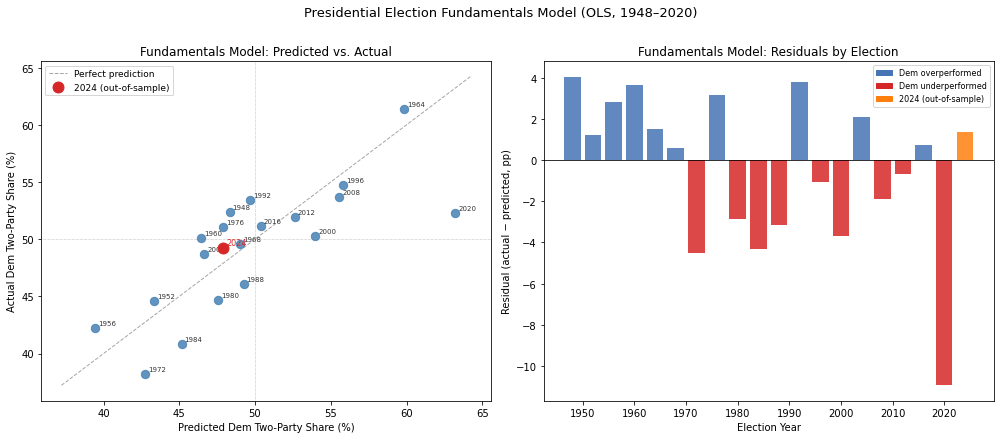

Saved: outputs/figures/fundamentals_model.png


In [13]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# --- Left: Predicted vs. Actual ---
ax1.scatter(loo_df['predicted_dem'], loo_df['actual_dem'],
            color='steelblue', s=70, zorder=3, alpha=0.85)
for _, r in loo_df.iterrows():
    ax1.annotate(str(int(r['year'])), (r['predicted_dem'], r['actual_dem']),
                 fontsize=7, xytext=(3, 3), textcoords='offset points', color='#333')
ax1.scatter([pred_2024_dem], [actual_2024],
            color='#d62728', s=120, zorder=4, label='2024 (out-of-sample)')
ax1.annotate('2024', (pred_2024_dem, actual_2024), color='#d62728',
             fontsize=8, xytext=(3, 3), textcoords='offset points')
lo = min(loo_df['predicted_dem'].min(), loo_df['actual_dem'].min()) - 1
hi = max(loo_df['predicted_dem'].max(), loo_df['actual_dem'].max()) + 1
ax1.plot([lo, hi], [lo, hi], 'k--', alpha=0.35, linewidth=1, label='Perfect prediction')
ax1.axhline(50, color='gray', linewidth=0.5, linestyle=':')
ax1.axvline(50, color='gray', linewidth=0.5, linestyle=':')
ax1.set_xlabel('Predicted Dem Two-Party Share (%)')
ax1.set_ylabel('Actual Dem Two-Party Share (%)')
ax1.set_title('Fundamentals Model: Predicted vs. Actual')
ax1.legend(fontsize=9)

# --- Right: Residuals ---
all_years = list(loo_df['year']) + [2024]
all_resid = list(loo_df['residual_dem']) + [residual_2024]
bar_colors = ['#4575b4' if r >= 0 else '#d62728' for r in all_resid]
bar_colors[-1] = '#ff7f0e'  # 2024 in orange = out-of-sample

ax2.bar(all_years, all_resid, color=bar_colors, width=3.2, alpha=0.85)
ax2.axhline(0, color='black', linewidth=0.8)
ax2.set_xlabel('Election Year')
ax2.set_ylabel('Residual (actual âˆ’ predicted, pp)')
ax2.set_title('Fundamentals Model: Residuals by Election')
ax2.legend(handles=[
    mpatches.Patch(color='#4575b4', label='Dem overperformed'),
    mpatches.Patch(color='#d62728', label='Dem underperformed'),
    mpatches.Patch(color='#ff7f0e', label='2024 (out-of-sample)'),
], fontsize=8)

plt.suptitle('Presidential Election Fundamentals Model (OLS, 1948â€“2020)', fontsize=13, y=1.01)
plt.tight_layout()
Path('../outputs/figures').mkdir(parents=True, exist_ok=True)
plt.savefig('../outputs/figures/fundamentals_model.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: outputs/figures/fundamentals_model.png")

In [14]:
from pathlib import Path

tables_dir = Path('../outputs/tables')
tables_dir.mkdir(parents=True, exist_ok=True)

coef_df = pd.DataFrame({
    'coefficient': model.params.round(4),
    'std_err':     model.bse.round(4),
    't_stat':      model.tvalues.round(3),
    'p_value':     model.pvalues.round(4),
}).rename_axis('variable')
coef_df.to_csv(tables_dir / 'fundamentals_model_coefficients.csv')
loo_df.to_csv(tables_dir / 'fundamentals_loocv_predictions.csv', index=False)

print("Saved:")
print(f"  outputs/tables/fundamentals_model_coefficients.csv")
print(f"  outputs/tables/fundamentals_loocv_predictions.csv")

Saved:
  outputs/tables/fundamentals_model_coefficients.csv
  outputs/tables/fundamentals_loocv_predictions.csv
